# Pesos por muestra, remuestreo y ensembles — respuesta al feedback del profesor

**Objetivo.** Responder, con la misma validación temporal de todo el proyecto, a las cuatro observaciones del profesor sobre la segunda entrega:

1. **¿Probaron ensembles y PCA?** PCA ya está en `04_modelo` (Paso 9, pregunta P3) y el *ensemble* por promedio en `04_modelo` (Paso 7). Aquí se completan los ensembles: promedio **sin el SVM** (que arrastraba al promedio), promedio **ponderado** y **stacking** con un meta-modelo, más un **Random Forest** de clasificación (el modelo que Tammouch et al. encuentran peor).
2. **Un enfoque *data-centric*.** Las muestras donde la cuota acierta (el favorito gana) son mayoría en el entrenamiento. Se prueba **dar más peso** a las muestras donde la cuota falla (pesos por muestra) y **remuestrear** el entrenamiento al 50% aciertos / 50% fallos.
3. **Comparar siempre con las cuotas de forma directa.** Todo se mide frente al mercado crudo (consenso) y a Pinnacle cruda, y se construye un **cuadro único** de comparación directa en validación y en el test holdout.
4. **El modelo sin cuotas como predictor de cuotas.** Se presenta el modelo de fundamentos (plantilla, Elo, medias exponenciales, habilidades) como un generador de precios y se mide cuánto del mercado reproduce.

**Cómo leer este cuaderno.** Cada celda de código va precedida por una celda de texto (qué vamos a hacer y por qué) y seguida por otra (qué encontramos, qué significa para nuestro caso y la decisión).

| Paso | Qué hace |
|---|---|
| 0 | Carga, utilidades y definición de "la cuota acierta" |
| 1 | Pesos por muestra: más peso a los partidos donde la cuota falla |
| 2 | Remuestreo 50/50 y recalibración posterior |
| 3 | Ensembles revisados: promedio sin SVM, ponderado, stacking y Random Forest |
| 4 | El modelo sin cuotas como predictor de cuotas |
| 5 | Cuadro único de comparación directa (validación y test holdout) |

**Entrada.** `dataset_final.csv`, `dataset_extra.csv`, `dataset_skills.csv`, `backtest_odds.csv`, `matches_clean.csv` (cuotas de Pinnacle), `feature_sets.json`, `hiperparametros.json`, `modelo_final.json`, `modelos_oof.csv` (04), `predicciones_oof.csv` (06), `modelo_final_oof.csv` y `modelo_final_test.csv` (08). **Salida.** `pesos_resultados.csv`, `remuestreo_resultados.csv`, `ensembles_resultados.csv`, `predictor_cuotas.csv`, `comparacion_directa.csv` y las figuras `docs/figures/p_pesos.png`, `p_ensembles.png`, `p_predictor_cuotas.png`.

> **Regla de este cuaderno.** Todo experimento nuevo se evalúa **solo en las 6 temporadas de validación** (2018/19–2023/24). El test holdout (2024/25–2025/26) ya se evaluó **una única vez** en `08_modelo_final` y aquí solo se **reproduce** para el cuadro del Paso 5; ninguna variante nueva se mide en el test, porque ninguna gana en validación y volver a usar el test lo convertiría en una segunda validación.

> **Terminología (igual en todo el proyecto).** *Referencias sin aprendizaje*: el **prior** y el **mercado crudo** (consenso de B365, BW, WH y PS) o **Pinnacle cruda**. ***Baseline***: la regresión logística sobre las tres variables de mercado ("LR (cuotas)"). **Modelo final**: la regresión logística de dos variables sobre la apertura de Pinnacle (con respaldo del consenso).

## Paso 0 — Carga, utilidades y definición de "la cuota acierta"

**Qué vamos a hacer.** Cargar los datos y reutilizar las utilidades de `08_modelo_final` (validación temporal expansiva de 6 folds, log loss, RPS, AUC, ECE de igual masa, comparación pareada con *bootstrap* por bloques temporada–semana y corrección de Benjamini–Hochberg). Se define **"la cuota acierta"** como: el resultado más probable según el mercado crudo (consenso) coincide con el resultado real. Se preparan las cuatro matrices de variables que se usarán con pesos: las 3 variables de mercado del *baseline*, las 2 variables de Pinnacle del modelo final, el bloque F2 (33 variables, con nulos) para HGB y el bloque **sin cuotas** (plantilla normalizada, Elo, medias exponenciales y 33 habilidades, el mismo de `06_mercado`).

**Por qué.** Para que todo lo nuevo se mida con la misma vara que los cuadernos anteriores y las cifras sean comparables. La tasa de acierto del mercado fija cuán desbalanceado está el entrenamiento entre "aciertos" y "fallos", que es la premisa del experimento *data-centric*.

In [1]:
import json, warnings, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import minimize
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.metrics import log_loss, roc_auc_score, accuracy_score

warnings.filterwarnings('ignore')
DATA, FIG = '../data/', '../../docs/figures/'
df = pd.read_csv(DATA + 'dataset_final.csv'); odds = pd.read_csv(DATA + 'backtest_odds.csv')
EXTRA = pd.read_csv(DATA + 'dataset_extra.csv'); sk = pd.read_csv(DATA + 'dataset_skills.csv')
for t in (odds, EXTRA, sk):
    assert (t[['Date', 'HomeTeam', 'AwayTeam']].values == df[['Date', 'HomeTeam', 'AwayTeam']].values).all()
fs = json.load(open(DATA + 'feature_sets.json')); HP = json.load(open(DATA + 'hiperparametros.json')); MF = json.load(open(DATA + 'modelo_final.json'))
y = df['FTR'].map({'H': 0, 'D': 1, 'A': 2}).to_numpy(); seas = df['Season'].to_numpy(); liga = df['Div'].to_numpy()
TEST_SEASONS = [2425, 2526]; TEST_MASK = np.isin(seas, TEST_SEASONS); TV = ~TEST_MASK
TEMP = sorted(np.unique(seas)); TEMP_TV = [s for s in TEMP if s not in TEST_SEASONS]
FOLDS = [s for s in TEMP if s >= 1819 and s not in TEST_SEASONS]; EV = (seas >= 1819) & TV
assert max(FOLDS) < min(TEST_SEASONS)
fechas = pd.to_datetime(df['Date'], dayfirst=True, format='mixed')
bloque = pd.factorize(df['Season'].astype(str) + '-' + fechas.dt.isocalendar().week.astype(str).to_numpy())[0]
rng = np.random.default_rng(88)

# --- probabilidades del mercado: consenso crudo y Pinnacle cruda (con respaldo), como en 08
Pmk = odds[['MKT_pH', 'MKT_pD', 'MKT_pA']].to_numpy(float)
e_ = np.exp(EXTRA['REF_logit'].to_numpy()); pD_ = EXTRA['REF_pD'].to_numpy()
Ppin = np.c_[(1 - pD_) * e_ / (1 + e_), pD_, (1 - pD_) / (1 + e_)]
assert np.allclose(Ppin.sum(1), 1)
acierta = Pmk.argmax(1) == y                      # "la cuota acierta": el favorito del mercado gana

# --- matrices de variables
MKT3 = ['MKT_logit', 'MKT_pD', 'MKT_margin']; REF2 = ['REF_logit', 'REF_pD']; F2 = fs['F2_completo']; SK = fs['SK_habilidades']
FUERZA = ['SQz_H', 'SQz_DIF', 'ELO_DIF', 'EWP10_DIF', 'EWG10_DIF']
X_MKT = df[MKT3].to_numpy(float); X_REF = EXTRA[REF2].to_numpy(float); X_F2 = df[F2].to_numpy(float)
X_NM = np.c_[EXTRA[FUERZA].to_numpy(float), sk[SK].to_numpy(float)]
assert not np.isnan(X_MKT).any() and not np.isnan(X_REF).any() and not np.isnan(X_NM).any()

# --- utilidades (identicas a 08_modelo_final)
def loss_vec(Pm):
    o = np.full(len(y), np.nan); ok = ~np.isnan(Pm[:, 0]); o[ok] = -np.log(np.clip(Pm[ok, y[ok]], 1e-9, 1)); return o
def rps(Pm, yv):
    O = np.eye(3)[yv]; return float(np.mean(0.5 * (((np.cumsum(Pm, 1) - np.cumsum(O, 1))[:, :2]) ** 2).sum(1)))
def aucs(Pm, yv): return [roc_auc_score(yv == j, Pm[:, j]) for j in range(3)]
def ece_q(p, o, nb=10):
    b = pd.qcut(p, nb, labels=False, duplicates='drop'); return float(sum((b == k).mean() * abs(o[b == k].mean() - p[b == k].mean()) for k in np.unique(b)))
def comparar(la, lb, B=2000, mask=None):
    ok = ~np.isnan(la) & ~np.isnan(lb)
    if mask is not None: ok &= mask
    d = (la - lb)[ok]; b = bloque[ok]; cod, K = pd.factorize(b)[0], len(np.unique(b))
    sm = np.bincount(cod, weights=d, minlength=K); cn = np.bincount(cod, minlength=K).astype(float)
    ix = rng.integers(0, K, (B, K)); bs = sm[ix].sum(1) / cn[ix].sum(1); fo = pd.Series(d).groupby(seas[ok]).mean()
    p = float(max(2 * min((bs <= 0).mean(), (bs >= 0).mean()), 1 / B))
    return dict(delta=float(d.mean()), lo=float(np.percentile(bs, 2.5)), hi=float(np.percentile(bs, 97.5)), folds=f'{int((fo < 0).sum())}/{len(fo)}', p=p)
def bh(p):
    p = np.asarray(p); o = np.argsort(p); m = len(p); adj = np.empty(m); adj[o] = np.minimum.accumulate((p[o] * m / (np.arange(m) + 1))[::-1])[::-1]; return np.minimum(adj, 1)
def metricas(Pm, mask=EV):
    ok = mask & ~np.isnan(Pm[:, 0]); pr, yv = Pm[ok], y[ok]; pred = pr.argmax(1); fa = ~acierta[ok]
    return dict(n=int(ok.sum()), log_loss=log_loss(yv, pr, labels=[0, 1, 2]), RPS=rps(pr, yv), AUC_macro=float(np.mean(aucs(pr, yv))),
                ECE_masa=float(np.mean([ece_q(pr[:, j], yv == j) for j in range(3)])), acc=accuracy_score(yv, pred),
                acc_fallos_mercado=float((pred[fa] == yv[fa]).mean()), recall_empate=float((pred[yv == 1] == 1).mean()), empates_predichos=float((pred == 1).mean()), P_empate_media=float(pr[:, 1].mean()))
def forest(ax, nombres, delta, lo, hi, titulo, xlabel='Δ log loss (negativo = mejor que la referencia)', fmt='{:+.4f}', positivo_bueno=False):
    ypos = np.arange(len(nombres))[::-1]
    for yi, d, l, h in zip(ypos, delta, lo, hi):
        ref = (l == h == 0) or np.isnan(l)
        bueno_, malo_ = (l > 0, h < 0) if positivo_bueno else (h < 0, l > 0)
        c = 'black' if ref else ('tab:green' if bueno_ else 'tab:red' if malo_ else 'gray')
        if not ref: ax.plot([l, h], [yi, yi], color=c, lw=2.2)
        ax.plot(d, yi, 'o' if not ref else 's', color=c, ms=5)
        ax.annotate(fmt.format(d), (d if ref else max(d, h), yi), xytext=(4, 0), textcoords='offset points', va='center', fontsize=7, color=c)
    ax.axvline(0, color='k', lw=0.8); ax.set_yticks(ypos); ax.set_yticklabels(nombres, fontsize=8); ax.set_title(titulo, fontsize=10); ax.set_xlabel(xlabel, fontsize=8)
    ax.margins(x=0.18)

# --- fabricas de modelos con los hiperparametros ya elegidos (04 y 08); ninguno se reelige aqui
lr = lambda C: (lambda: make_pipeline(StandardScaler(), LogisticRegression(C=C, max_iter=5000)))
hgb = lambda: HistGradientBoostingClassifier(learning_rate=HP['HGB_clas']['learning_rate'], max_depth=int(HP['HGB_clas']['max_depth']), min_samples_leaf=int(HP['HGB_clas']['min_samples_leaf']), max_iter=int(HP['HGB_clas']['max_iter']), random_state=0)
MODELOS = {'LR (cuotas), baseline': (lr(HP['LR_clas']['C']), X_MKT), 'Modelo final (LR 2 var. Pinnacle)': (lr(MF['C']), X_REF),
           'HGB (F2)': (hgb, X_F2), 'LR sin cuotas (fuerza + habilidades)': (lr(HP['LR_clas']['C']), X_NM)}
def fit_w(m, X, yy, w):
    if w is None: return m.fit(X, yy)
    return m.fit(X, yy, **{m.steps[-1][0] + '__sample_weight': w}) if hasattr(m, 'steps') else m.fit(X, yy, sample_weight=w)
def cv_proba_w(fab, X, pesos=None, folds=FOLDS):
    # pesos: funcion (mascara de entrenamiento) -> vector de pesos para esas filas, o None
    Pm = np.full((len(y), 3), np.nan)
    for s in folds:
        tr, va = seas < s, seas == s
        Pm[va] = fit_w(fab(), X[tr], y[tr], None if pesos is None else pesos(tr)).predict_proba(X[va])
    return Pm
Pmk_ev = np.where(EV[:, None], Pmk, np.nan); Ppin_ev = np.where(EV[:, None], Ppin, np.nan)
L_mk, L_pin = loss_vec(Pmk_ev), loss_vec(Ppin_ev)
print('filas:', len(df), '| train/val:', int(TV.sum()), '| test holdout (no se usa en los Pasos 1-4):', int(TEST_MASK.sum()), '| folds:', [int(s) for s in FOLDS], '| partidos de validacion:', int(EV.sum()))
print(f'la cuota (consenso) acierta el resultado en el {acierta[TV].mean():.1%} de train/val ({int(acierta[TV].sum())} aciertos, {int((~acierta[TV]).sum())} fallos; razon {acierta[TV].sum() / (~acierta[TV]).sum():.2f}:1)')
print('acierto del mercado por resultado real -> H: %.1f%% | D: %.1f%% | A: %.1f%%' % tuple(100 * acierta[TV & (y == j)].mean() for j in range(3)))
print(f'log loss en validacion: mercado crudo {np.nanmean(L_mk[EV]):.4f} | Pinnacle cruda {np.nanmean(L_pin[EV]):.4f}')
print('log loss del mercado en sus aciertos: %.4f | en sus fallos: %.4f' % (np.nanmean(L_mk[EV & acierta]), np.nanmean(L_mk[EV & ~acierta])))

filas: 36119 | train/val: 30120 | test holdout (no se usa en los Pasos 1-4): 5999 | folds: [1819, 1920, 2021, 2122, 2223, 2324] | partidos de validacion: 18184
la cuota (consenso) acierta el resultado en el 54.0% de train/val (16278 aciertos, 13842 fallos; razon 1.18:1)
acierto del mercado por resultado real -> H: 83.3% | D: 0.1% | A: 55.2%
log loss en validacion: mercado crudo 0.9664 | Pinnacle cruda 0.9657
log loss del mercado en sus aciertos: 0.6087 | en sus fallos: 1.3838


**Qué encontramos.** 36,119 partidos: 30,120 de train/val y 5,999 de test holdout (no se usa en los Pasos 1–4). Validación: 6 temporadas, 18,184 partidos, log loss del mercado crudo 0.9664 y de Pinnacle cruda 0.9657, como en `04`, `07` y `08`. **La cuota acierta en el 54.0% de train/val** (16,278 aciertos frente a 13,842 fallos; razón 1.18:1). El desbalance es modesto, pero tiene estructura: el mercado acierta el 83.3% de las victorias locales, el 55.2% de las visitantes y el **0.1% de los empates** (el empate casi nunca es el resultado más probable). Su log loss es 0.609 cuando acierta y 1.384 cuando falla.

**Qué significa para nuestro caso.** "Dar más peso a los partidos donde la cuota falla" equivale, en la práctica, a dar más peso a los **empates y a las victorias visitantes**: los fallos del mercado no son un subconjunto raro y homogéneo de partidos "mal valorados", sino la mitad de los partidos, concentrada en dos de las tres clases. Por eso el experimento *data-centric* se interpreta junto con el *recall* del empate y la calibración: si solo mueve el *prior* de clases, lo veremos ahí.

**Decisión.** Mantener la definición simple de "acierto" (favorito del consenso gana) y medir todas las variantes con las mismas métricas y el mismo *bootstrap* por bloques que el resto del proyecto.

## Paso 1 — Pesos por muestra: más peso a los partidos donde la cuota falla

**Qué vamos a hacer.** Entrenar los cuatro modelos con `sample_weight` en los 6 folds temporales, con siete esquemas de peso para las muestras donde el mercado **falla** (el favorito no gana): sin pesos (referencia), peso 2, 3 y 5, "50/50 por peso" (el peso que iguala la masa total de aciertos y fallos en cada entrenamiento), y dos pesos continuos que crecen con la sorpresa: $1/p_{\text{mercado}}(y)$ y su raíz cuadrada. Los pesos se normalizan a media 1 para que la regularización signifique lo mismo en todos los casos. Se mide el log loss (métrica principal), la calibración (ECE de igual masa), el acierto global, el **acierto en los partidos donde el mercado falla**, el *recall* del empate y la probabilidad media de empate; cada variante se compara con su versión sin pesos y con el mercado crudo mediante *bootstrap* por bloques, con Benjamini–Hochberg sobre toda la familia.

**Por qué.** Es la propuesta *data-centric* del profesor: si los aciertos del mercado dominan el entrenamiento, el modelo podría estar "copiando" al mercado y perdiendo lo que ocurre en las sorpresas. Si dar más peso a las sorpresas mejora el log loss, hay información que el entrenamiento ordinario desaprovecha; si solo mejora el acierto en sorpresas a costa del log loss y la calibración, el efecto es un cambio de *prior* (más empates y visitantes predichos), no información nueva. Las dos cosas se pueden distinguir con las métricas elegidas.

LR (cuotas), baseline: listo (1 s)


Modelo final (LR 2 var. Pinnacle): listo (1 s)


HGB (F2): listo (166 s)


LR sin cuotas (fuerza + habilidades): listo (171 s)
                              modelo              esquema  log_loss  delta_vs_sin_pesos      lo     hi folds_mejora   p_BH  delta_vs_mercado  ECE_masa    acc  acc_fallos_mercado  recall_empate  empates_predichos  P_empate_media
               LR (cuotas), baseline            sin pesos    0.9657              0.0000  0.0000 0.0000            -    NaN           -0.0007    0.0087 0.5379              0.0045         0.0007             0.0005          0.2442
               LR (cuotas), baseline   w = 2 a los fallos    1.0044              0.0386  0.0347 0.0425          0/6 0.0005            0.0379    0.0787 0.5011              0.2364         0.4393             0.3599          0.3283
               LR (cuotas), baseline   w = 3 a los fallos    1.0623              0.0966  0.0906 0.1027          0/6 0.0005            0.0959    0.1113 0.4001              0.4356         0.7982             0.6967          0.3746
               LR (cuotas), baseline

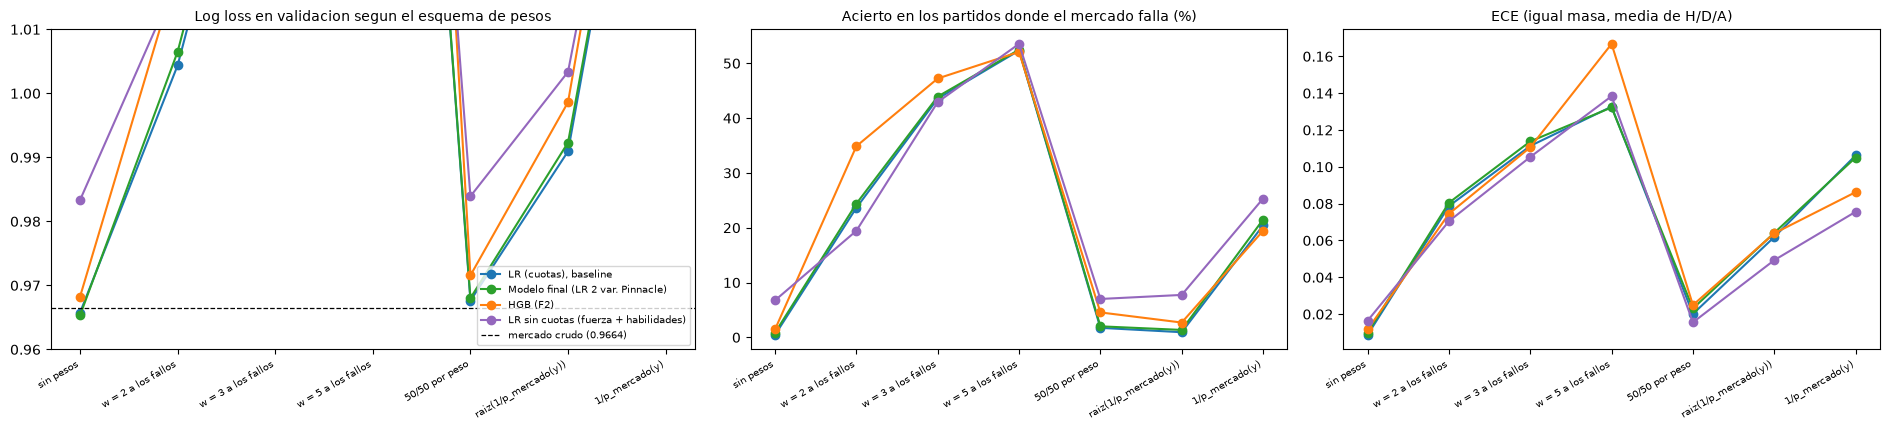

In [2]:
def esquema(nombre):
    def f(tr):
        fa = ~acierta[tr]
        if nombre == 'sin pesos': w = np.ones(tr.sum())
        elif nombre.startswith('w = '): w = np.where(fa, float(nombre.split('= ')[1].split(' ')[0]), 1.0)
        elif nombre == '50/50 por peso': w = np.where(fa, (~fa).sum() / fa.sum(), 1.0)
        elif nombre == '1/p_mercado(y)': w = 1 / np.clip(Pmk[tr][np.arange(tr.sum()), y[tr]], 0.02, 1)
        elif nombre == 'raiz(1/p_mercado(y))': w = np.sqrt(1 / np.clip(Pmk[tr][np.arange(tr.sum()), y[tr]], 0.02, 1))
        return w / w.mean()
    return f
ESQUEMAS = ['sin pesos', 'w = 2 a los fallos', 'w = 3 a los fallos', 'w = 5 a los fallos', '50/50 por peso', 'raiz(1/p_mercado(y))', '1/p_mercado(y)']
t0 = time.time(); P_pesos, filas = {}, []
for nm, (fab, X) in MODELOS.items():
    for es in ESQUEMAS:
        P_pesos[(nm, es)] = cv_proba_w(fab, X, esquema(es))
    L0 = loss_vec(P_pesos[(nm, 'sin pesos')])
    for es in ESQUEMAS:
        L = loss_vec(P_pesos[(nm, es)]); m = metricas(P_pesos[(nm, es)])
        c0 = comparar(L, L0) if es != 'sin pesos' else dict(delta=0.0, lo=0.0, hi=0.0, folds='-', p=np.nan); cm = comparar(L, L_mk)
        filas.append(dict(modelo=nm, esquema=es, **m, delta_vs_sin_pesos=c0['delta'], lo=c0['lo'], hi=c0['hi'], folds_mejora=c0['folds'], p_vs_sin_pesos=c0['p'],
                          delta_vs_mercado=cm['delta'], lo_mercado=cm['lo'], hi_mercado=cm['hi'], folds_mejora_mercado=cm['folds']))
    print(f'{nm}: listo ({time.time() - t0:.0f} s)')
pesos = pd.DataFrame(filas); ok = pesos.esquema != 'sin pesos'; pesos.loc[ok, 'p_BH'] = bh(pesos.loc[ok, 'p_vs_sin_pesos'].values)
pesos.to_csv(DATA + 'pesos_resultados.csv', index=False)
cols = ['modelo', 'esquema', 'log_loss', 'delta_vs_sin_pesos', 'lo', 'hi', 'folds_mejora', 'p_BH', 'delta_vs_mercado', 'ECE_masa', 'acc', 'acc_fallos_mercado', 'recall_empate', 'empates_predichos', 'P_empate_media']
print(pesos[cols].round(4).to_string(index=False))
# el peso medio efectivo de los fallos en cada esquema (ultimo fold), para interpretar
tr_ = seas < FOLDS[-1]
print('\npeso medio de los fallos / peso medio de los aciertos (entrenamiento del ultimo fold):', {es: round(float(esquema(es)(tr_)[~acierta[tr_]].mean() / esquema(es)(tr_)[acierta[tr_]].mean()), 2) for es in ESQUEMAS})

fig, axs = plt.subplots(1, 3, figsize=(19, 4.4), gridspec_kw={'width_ratios': [1.2, 1, 1]})
colores = dict(zip(MODELOS, ['tab:blue', 'tab:green', 'tab:orange', 'tab:purple'])); xs = np.arange(len(ESQUEMAS))
for nm in MODELOS:
    sub = pesos[pesos.modelo == nm].set_index('esquema').loc[ESQUEMAS]
    axs[0].plot(xs, sub.log_loss, marker='o', color=colores[nm], label=nm); axs[1].plot(xs, sub.acc_fallos_mercado * 100, marker='o', color=colores[nm]); axs[2].plot(xs, sub.ECE_masa, marker='o', color=colores[nm])
axs[0].axhline(np.nanmean(L_mk[EV]), color='k', ls='--', lw=0.9, label=f'mercado crudo ({np.nanmean(L_mk[EV]):.4f})'); axs[0].set_ylim(0.96, 1.01); axs[0].legend(fontsize=7); axs[0].set_title('Log loss en validacion segun el esquema de pesos', fontsize=10)
axs[1].set_title('Acierto en los partidos donde el mercado falla (%)', fontsize=10); axs[2].set_title('ECE (igual masa, media de H/D/A)', fontsize=10)
for ax in axs: ax.set_xticks(xs); ax.set_xticklabels(ESQUEMAS, rotation=30, ha='right', fontsize=7)
plt.tight_layout(); plt.show()

**Qué encontramos.** Log loss medio en las 6 temporadas (entre paréntesis, Δ frente a la misma versión sin pesos; IC del 95% por bloques):

| Esquema (peso de los fallos / aciertos) | LR cuotas (*baseline*) | Modelo final | HGB (F2) | LR sin cuotas |
|---|---|---|---|---|
| sin pesos (1.0) | **0.9657** | **0.9653** | **0.9682** | **0.9833** |
| 50/50 por peso (1.17) | 0.9676 (+0.0019) | 0.9680 (+0.0027) | 0.9716 (+0.0033) | 0.9839 (+0.0006, IC incluye 0) |
| √(1/p_mercado(y)) (1.47) | 0.9909 (+0.0252) | 0.9923 (+0.0270) | 0.9986 (+0.0304) | 1.0034 (+0.0200) |
| w = 2 (2.0) | 1.0044 (+0.0386) | 1.0065 (+0.0412) | 1.0193 (+0.0511) | 1.0179 (+0.0346) |
| 1/p_mercado(y) (2.19) | 1.0751 (+0.1094) | 1.0752 (+0.1099) | 1.0863 (+0.1181) | 1.0821 (+0.0987) |
| w = 3 (3.0) | 1.0623 (+0.0966) | 1.0646 (+0.0992) | 1.0969 (+0.1287) | 1.0750 (+0.0917) |
| w = 5 (5.0) | 1.1726 (+0.2069) | 1.1723 (+0.2070) | 1.2326 (+0.2644) | 1.1826 (+0.1993) |

Los 24 contrastes tienen *p* ajustado (Benjamini–Hochberg) < 0.001 salvo el "50/50 por peso" del modelo sin cuotas (*p* = 0.23, indistinguible de 0): **ninguna variante con pesos mejora el log loss en ninguna temporada** (0/6 en todos los casos). Lo que sí cambia es la composición de las predicciones. Para el *baseline*: con w = 2 el acierto en los partidos donde el mercado falla sube del 0.5% al 23.6% y el *recall* del empate del 0.1% al 43.9%, pero el acierto global baja del 53.8% al 50.1%, la probabilidad media de empate pasa de 0.244 a 0.328 (la frecuencia real es 0.249) y el ECE se multiplica por nueve (0.0087 → 0.0787). Con w = 5 el modelo predice empate en el 89% de los partidos.

**Qué significa para nuestro caso.** Reponderar los fallos del mercado no extrae información nueva: desplaza masa de probabilidad hacia el empate y el visitante en *todos* los partidos, lo que equivale a cambiar el *prior* de clases de un modelo que ya estaba calibrado. El log loss es una regla de puntuación propia: se minimiza con la probabilidad verdadera, de modo que cualquier reponderación que altere la frecuencia efectiva de las clases solo puede empeorarlo, como se ve en la tabla. La ganancia aparente en el acierto de las sorpresas es el mismo fenómeno visto desde la *accuracy*: el modelo acierta más empates porque predice muchos más empates, no porque sepa cuáles serán. El modelo sin cuotas es el único donde el efecto del peso suave es nulo, porque sus variables no contienen el precio y no reproducen tan bien la estructura de aciertos del mercado.

**Decisión.** No se adopta ningún esquema de pesos. La Fig. `p_pesos.png` (generada en el Paso 2 con el remuestreo) resume el resultado para el informe.

## Paso 2 — Remuestreo 50/50 y recalibración posterior

**Qué vamos a hacer.** Repetir el experimento con **remuestreo** del entrenamiento en lugar de pesos, en dos variantes: *submuestreo* (se descartan aciertos del mercado al azar hasta igualar a los fallos) y *sobremuestreo* (se repiten fallos al azar hasta igualar a los aciertos), con 3 semillas cada una (se promedia la pérdida por partido de las 3 semillas). Después, para el *baseline* remuestreado, se ajusta una **recalibración posterior** (regresión logística sobre sus logits, aprendida en la temporada anterior a la que se predice, sin ver la temporada evaluada) para ver cuánto del log loss se recupera al deshacer el cambio de escala.

**Por qué.** El remuestreo 50/50 es la otra forma que propone el profesor de equilibrar aciertos y fallos. Si lo que cambia es solo la escala de las probabilidades (el *prior*), una recalibración posterior devolverá al modelo remuestreado casi al mismo log loss que el modelo ordinario; si el remuestreo hubiera extraído información nueva, la recalibración la conservaría y el log loss quedaría por debajo del ordinario.

LR (cuotas), baseline: listo (2 s)


Modelo final (LR 2 var. Pinnacle): listo (4 s)


HGB (F2): listo (12 s)


LR sin cuotas (fuerza + habilidades): listo (19 s)
                              modelo             esquema  log_loss  delta_vs_sin_pesos      lo     hi folds_mejora   p_BH  delta_vs_mercado  ECE_masa    acc  acc_fallos_mercado  recall_empate  empates_predichos
               LR (cuotas), baseline   submuestreo 50/50    0.9676              0.0019  0.0009 0.0029          0/6 0.0006            0.0012    0.0200 0.5383              0.0167         0.0145             0.0102
               LR (cuotas), baseline sobremuestreo 50/50    0.9679              0.0021  0.0012 0.0031          0/6 0.0006            0.0014    0.0200 0.5377              0.0178         0.0150             0.0112
   Modelo final (LR 2 var. Pinnacle)   submuestreo 50/50    0.9681              0.0028  0.0018 0.0037          0/6 0.0006            0.0016    0.0233 0.5368              0.0196         0.0179             0.0145
   Modelo final (LR 2 var. Pinnacle) sobremuestreo 50/50    0.9682              0.0029  0.0020 0.0038    

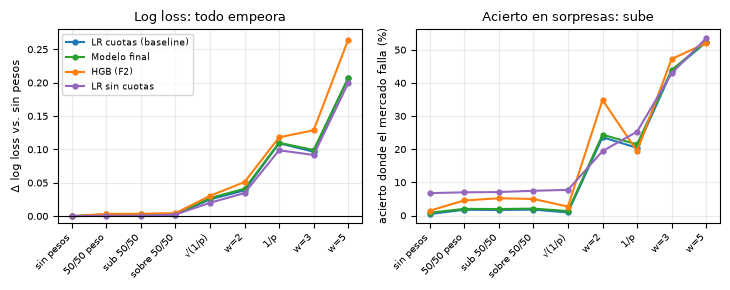

In [3]:
def cv_proba_remuestreo(fab, X, modo, semilla, folds=FOLDS):
    r = np.random.default_rng(semilla); Pm = np.full((len(y), 3), np.nan)
    for s in folds:
        tr, va = seas < s, seas == s; itr = np.where(tr)[0]; ia, ifa = itr[acierta[itr]], itr[~acierta[itr]]
        idx = np.r_[r.choice(ia, len(ifa), replace=False), ifa] if modo == 'submuestreo' else np.r_[ia, r.choice(ifa, len(ia), replace=True)]
        Pm[va] = fab().fit(X[idx], y[idx]).predict_proba(X[va])
    return Pm
t0 = time.time(); P_rem, filas = {}, []
for nm, (fab, X) in MODELOS.items():
    L0 = loss_vec(P_pesos[(nm, 'sin pesos')])
    for modo in ('submuestreo 50/50', 'sobremuestreo 50/50'):
        Ps = [cv_proba_remuestreo(fab, X, modo.split()[0], sem) for sem in (0, 1, 2)]; P_rem[(nm, modo)] = Ps
        Lm = np.mean([loss_vec(P) for P in Ps], axis=0); m = {k: float(np.mean([metricas(P)[k] for P in Ps])) for k in metricas(Ps[0])}
        c0, cm = comparar(Lm, L0), comparar(Lm, L_mk)
        filas.append(dict(modelo=nm, esquema=modo, **m, delta_vs_sin_pesos=c0['delta'], lo=c0['lo'], hi=c0['hi'], folds_mejora=c0['folds'], p_vs_sin_pesos=c0['p'], delta_vs_mercado=cm['delta'], lo_mercado=cm['lo'], hi_mercado=cm['hi']))
    print(f'{nm}: listo ({time.time() - t0:.0f} s)')
rem = pd.DataFrame(filas); rem['p_BH'] = bh(rem.p_vs_sin_pesos.values); rem.to_csv(DATA + 'remuestreo_resultados.csv', index=False)
print(rem[['modelo', 'esquema', 'log_loss', 'delta_vs_sin_pesos', 'lo', 'hi', 'folds_mejora', 'p_BH', 'delta_vs_mercado', 'ECE_masa', 'acc', 'acc_fallos_mercado', 'recall_empate', 'empates_predichos']].round(4).to_string(index=False))

# --- recalibracion posterior del baseline remuestreado (submuestreo, semilla 0): calibrador aprendido en la temporada anterior, sin ver la evaluada
def logit3(P): Z = np.log(np.clip(P, 1e-9, 1)); return Z - Z.mean(1, keepdims=True)
prev_de = {s: TEMP[TEMP.index(s) - 1] for s in TEMP[1:]}
fab, X = MODELOS['LR (cuotas), baseline']; r = np.random.default_rng(0); P_recal = np.full((len(y), 3), np.nan)
for s in FOLDS:
    p = prev_de[s]; tr_c, ca, tr, va = seas < p, seas == p, seas < s, seas == s
    def ajuste(mask):
        itr = np.where(mask)[0]; ia, ifa = itr[acierta[itr]], itr[~acierta[itr]]; idx = np.r_[r.choice(ia, len(ifa), replace=False), ifa]; return fab().fit(X[idx], y[idx])
    mc, m = ajuste(tr_c), ajuste(tr)
    cal = LogisticRegression(C=10.0, max_iter=3000).fit(logit3(mc.predict_proba(X[ca])), y[ca])
    P_recal[va] = cal.predict_proba(logit3(m.predict_proba(X[va])))
L_sub = loss_vec(P_rem[('LR (cuotas), baseline', 'submuestreo 50/50')][0]); L_rec = loss_vec(P_recal); L_base = loss_vec(P_pesos[('LR (cuotas), baseline', 'sin pesos')])
c_rec = comparar(L_rec, L_base)
print(f"\nBaseline: sin pesos {np.nanmean(L_base[EV]):.4f} | submuestreo 50/50 {np.nanmean(L_sub[EV]):.4f} | submuestreo + recalibracion posterior {np.nanmean(L_rec[EV]):.4f}")
print(f"recalibrado - sin pesos: {c_rec['delta']:+.4f} [{c_rec['lo']:+.4f}, {c_rec['hi']:+.4f}], mejora en {c_rec['folds']} temporadas, p = {c_rec['p']:.3f}")
mr = metricas(P_recal); print('recalibrado -> acierto en fallos del mercado: %.3f | recall empate: %.3f | empates predichos: %.3f | ECE: %.4f' % (mr['acc_fallos_mercado'], mr['recall_empate'], mr['empates_predichos'], mr['ECE_masa']))

# --- figura para el informe: pesos y remuestreo en un solo panel doble (ancho de columna)
tabla_fig = pd.concat([pesos, rem], ignore_index=True)
orden = ['sin pesos', '50/50 por peso', 'submuestreo 50/50', 'sobremuestreo 50/50', 'raiz(1/p_mercado(y))', 'w = 2 a los fallos', '1/p_mercado(y)', 'w = 3 a los fallos', 'w = 5 a los fallos']
etiq = ['sin pesos', '50/50 peso', 'sub 50/50', 'sobre 50/50', '√(1/p)', 'w=2', '1/p', 'w=3', 'w=5']   # de menor a mayor peso efectivo de los fallos
fig, axs = plt.subplots(1, 2, figsize=(7.4, 3.0))
for nm, lab in zip(MODELOS, ['LR cuotas (baseline)', 'Modelo final', 'HGB (F2)', 'LR sin cuotas']):
    sub = tabla_fig[tabla_fig.modelo == nm].set_index('esquema').loc[orden]
    axs[0].plot(range(len(orden)), sub.delta_vs_sin_pesos, marker='o', ms=3.5, color=colores[nm], label=lab); axs[1].plot(range(len(orden)), sub.acc_fallos_mercado * 100, marker='o', ms=3.5, color=colores[nm])
axs[0].axhline(0, color='k', lw=0.8); axs[0].set_ylabel('Δ log loss vs. sin pesos', fontsize=8); axs[0].set_title('Log loss: todo empeora', fontsize=9); axs[0].legend(fontsize=6.5, loc='upper left'); axs[0].set_ylim(-0.01, 0.28)
axs[1].set_ylabel('acierto donde el mercado falla (%)', fontsize=8); axs[1].set_title('Acierto en sorpresas: sube', fontsize=9)
for ax in axs: ax.set_xticks(range(len(orden))); ax.set_xticklabels(etiq, rotation=45, ha='right', fontsize=7); ax.tick_params(axis='y', labelsize=7); ax.grid(alpha=0.25)
plt.tight_layout(); plt.savefig(FIG + 'p_pesos.png', dpi=200, bbox_inches='tight'); plt.show()

**Qué encontramos.** El remuestreo 50/50 reproduce al esquema "50/50 por peso": log loss 0.9676 (submuestreo) y 0.9679 (sobremuestreo) para el *baseline* (+0.0019 y +0.0021, 0/6 temporadas), 0.9681/0.9682 para el modelo final, 0.9718/0.9727 para HGB y 0.9839/0.9857 para el modelo sin cuotas; el ECE del *baseline* sube de 0.0087 a 0.0200 y la probabilidad media de empate a 0.265. La **recalibración posterior** del *baseline* submuestreado recupera la mitad de la pérdida (0.9677 → 0.9667) y devuelve el ECE a 0.0076 y el *recall* del empate a 1%, pero sigue +0.0010 [+0.0002, +0.0017] por encima del *baseline* ordinario (0/6 temporadas): la otra mitad es el coste de haber descartado el 8% de los partidos de entrenamiento.

**Qué significa para nuestro caso.** La recalibración confirma el diagnóstico del Paso 1: lo que el remuestreo cambia es la **escala** de las probabilidades (el *prior*), no el orden de los partidos; al deshacer el cambio de escala, el modelo vuelve casi al punto de partida y lo poco que falta es información perdida, no ganada. Si el remuestreo hubiera descubierto patrones en las sorpresas, el modelo recalibrado habría quedado por **debajo** de 0.9657.

**Decisión.** No se adopta el remuestreo. Para el informe: una fila en el cuadro de modelos ("mejor variante con pesos"), la Fig. `p_pesos.png` y un párrafo en la discusión con el argumento de la regla de puntuación propia.

## Paso 3 — Ensembles revisados: promedio sin SVM, ponderado, stacking y Random Forest

**Qué vamos a hacer.** Sobre las predicciones fuera de muestra que `04_modelo` guardó para LR, HGB, XGBoost, SVM y MLP (mismos folds), construir cuatro ensembles: (a) el **promedio original** de los cinco (ya reportado, 0.9685); (b) el **promedio sin el SVM**; (c) un **promedio ponderado** cuyos pesos minimizan el log loss en las temporadas de validación *anteriores* a la que se predice (validación anidada; en la primera temporada no hay predicciones previas y se usa el promedio sin SVM); (d) **stacking**: una regresión logística multinomial (meta-modelo) sobre los logits de los cinco modelos, ajustada también solo con las temporadas anteriores. Además se entrena un **Random Forest** de clasificación sobre F2 (nulos imputados con la mediana del entrenamiento) para completar la comparación con Tammouch et al. Todo se compara con la LR (*baseline*) y con el mercado crudo.

**Por qué.** El profesor pregunta por los ensembles; el promedio de `04_modelo` incluía al SVM, cuyas probabilidades estaban mal calibradas (log loss 0.994) y arrastraban al promedio. Un ensemble ponderado o apilado es la forma justa de preguntar si *combinar* los modelos añade algo a la LR: si el meta-modelo asigna casi todo el peso a la LR y no mejora el log loss, la respuesta es que los demás modelos no aportan información que la LR no tenga.

pesos optimos por temporada (aprendidos en las temporadas anteriores):
 temporada  LR (cuotas)  HGB (F1)  XGBoost (F2)  SVM (F1)  MLP (F1)
      1920        0.959       0.0         0.041       0.0       0.0
      2021        0.828       0.0         0.172       0.0       0.0
      2122        0.875       0.0         0.125       0.0       0.0
      2223        0.924       0.0         0.076       0.0       0.0
      2324        0.975       0.0         0.025       0.0       0.0

stacking: magnitud media de los coeficientes estandarizados por modelo:
 temporada  LR (cuotas)  HGB (F1)  XGBoost (F2)  SVM (F1)  MLP (F1)
      1920        0.364     0.094         0.166     0.090     0.112
      2021        0.286     0.072         0.083     0.080     0.137
      2122        0.242     0.087         0.027     0.048     0.133
      2223        0.227     0.079         0.040     0.046     0.142
      2324        0.242     0.144         0.029     0.026     0.112



Random Forest: listo (6 s)



                             modelo  log_loss    RPS  AUC_macro  ECE_masa    acc  delta_vs_LR      lo     hi folds_mejora   p_BH  delta_vs_mercado  lo_mercado  hi_mercado
              LR (cuotas), baseline    0.9657 0.1951     0.6836    0.0087 0.5379       0.0000  0.0000 0.0000            -    NaN           -0.0007     -0.0014      0.0001
      ALL (promedio de 5, original)    0.9686 0.1957     0.6821    0.0167 0.5381       0.0029  0.0019 0.0038          0/6 0.0009            0.0022      0.0014      0.0029
                   Promedio sin SVM    0.9668 0.1953     0.6828    0.0099 0.5384       0.0011  0.0005 0.0016          1/6 0.0009            0.0004     -0.0004      0.0012
                  Promedio LR + MLP    0.9661 0.1952     0.6834    0.0100 0.5381       0.0003 -0.0001 0.0007          1/6 0.1010           -0.0004     -0.0012      0.0005
Promedio ponderado (pesos anidados)    0.9661 0.1952     0.6831    0.0085 0.5382       0.0003  0.0000 0.0006          1/6 0.0268           -0.00

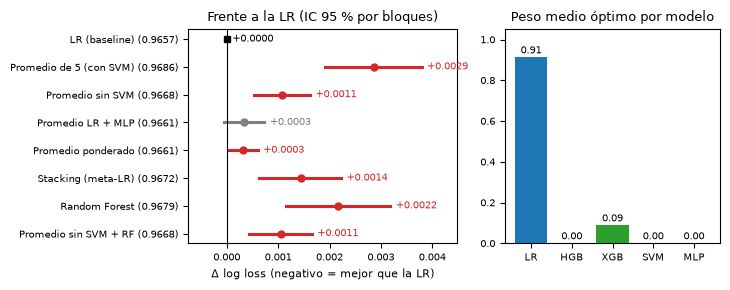

In [4]:
oof4 = pd.read_csv(DATA + 'modelos_oof.csv'); assert (oof4.y.values == y[oof4.idx.values]).all()
BASE = ['LR (cuotas)', 'HGB (F1)', 'XGBoost (F2)', 'SVM (F1)', 'MLP (F1)']
def full(P_rows, idx):
    Pm = np.full((len(y), 3), np.nan); Pm[idx] = P_rows; return Pm
P4 = {k: full(oof4[[f'{k}|H', f'{k}|D', f'{k}|A']].to_numpy(float), oof4.idx.values) for k in BASE + ['ALL (promedio)', 'mercado']}
assert abs(np.nanmean(loss_vec(P4['LR (cuotas)'])[EV]) - 0.9657) < 0.0002 and abs(np.nanmean(loss_vec(P4['mercado'])[EV]) - 0.9664) < 0.0002
SIN_SVM = [k for k in BASE if k != 'SVM (F1)']
ENS = {'ALL (promedio de 5, original)': P4['ALL (promedio)'], 'Promedio sin SVM': np.mean([P4[k] for k in SIN_SVM], axis=0), 'Promedio LR + MLP': np.mean([P4[k] for k in ('LR (cuotas)', 'MLP (F1)')], axis=0)}

def pesos_optimos(Ps, yy):
    # pesos en el simplex que minimizan el log loss del promedio ponderado (parametrizacion softmax)
    Z = np.stack(Ps, 0)
    def f(a):
        w = np.exp(a - a.max()); w /= w.sum(); P = np.tensordot(w, Z, 1); return log_loss(yy, P, labels=[0, 1, 2])
    a = minimize(f, np.zeros(len(Ps)), method='Nelder-Mead', options=dict(maxiter=4000, xatol=1e-4, fatol=1e-7)).x; w = np.exp(a - a.max()); return w / w.sum()
P_pond, P_stack, W_hist, coef_hist = np.full((len(y), 3), np.nan), np.full((len(y), 3), np.nan), [], []
for s in FOLDS:
    va = seas == s; prev = EV & (seas < s) & ~np.isnan(P4['LR (cuotas)'][:, 0])
    if prev.sum() == 0:
        P_pond[va] = ENS['Promedio sin SVM'][va]; P_stack[va] = ENS['Promedio sin SVM'][va]; continue
    w = pesos_optimos([P4[k][prev] for k in BASE], y[prev]); W_hist.append(dict(temporada=int(s), **dict(zip(BASE, np.round(w, 3)))))
    P_pond[va] = np.tensordot(w, np.stack([P4[k][va] for k in BASE], 0), 1)
    Zp = np.hstack([logit3(P4[k][prev])[:, :2] for k in BASE]); Zv = np.hstack([logit3(P4[k][va])[:, :2] for k in BASE])
    meta = make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=5000)).fit(Zp, y[prev]); P_stack[va] = meta.predict_proba(Zv)
    coef_hist.append(dict(temporada=int(s), **{k: round(float(np.abs(meta[-1].coef_[:, 2 * i:2 * i + 2]).mean()), 3) for i, k in enumerate(BASE)}))
ENS['Promedio ponderado (pesos anidados)'] = P_pond; ENS['Stacking (LR sobre logits, anidado)'] = P_stack
print('pesos optimos por temporada (aprendidos en las temporadas anteriores):'); print(pd.DataFrame(W_hist).to_string(index=False))
print('\nstacking: magnitud media de los coeficientes estandarizados por modelo:'); print(pd.DataFrame(coef_hist).to_string(index=False))

# --- Random Forest de clasificacion (F2 con imputacion por mediana del entrenamiento)
t0 = time.time()
rf = lambda: make_pipeline(SimpleImputer(strategy='median'), RandomForestClassifier(n_estimators=300, min_samples_leaf=int(HP['RF_reg']['min_samples_leaf']), max_features=float(HP['RF_reg']['max_features']), n_jobs=-1, random_state=0))
ENS['Random Forest (F2)'] = cv_proba_w(rf, X_F2); print(f'\nRandom Forest: listo ({time.time() - t0:.0f} s)')
ENS['Promedio sin SVM + RF'] = np.mean([P4[k] for k in SIN_SVM] + [ENS['Random Forest (F2)']], axis=0)

L_lr = loss_vec(P4['LR (cuotas)']); filas = []
for k, P in [('LR (cuotas), baseline', P4['LR (cuotas)'])] + list(ENS.items()):
    L = loss_vec(P); m = metricas(P); c = comparar(L, L_lr) if 'baseline' not in k else dict(delta=0.0, lo=0.0, hi=0.0, folds='-', p=np.nan); cm = comparar(L, L_mk)
    filas.append(dict(modelo=k, **m, delta_vs_LR=c['delta'], lo=c['lo'], hi=c['hi'], folds_mejora=c['folds'], p_vs_LR=c['p'], delta_vs_mercado=cm['delta'], lo_mercado=cm['lo'], hi_mercado=cm['hi'], folds_mejora_mercado=cm['folds']))
ens = pd.DataFrame(filas); ok = ens.modelo != 'LR (cuotas), baseline'; ens.loc[ok, 'p_BH'] = bh(ens.loc[ok, 'p_vs_LR'].values); ens.to_csv(DATA + 'ensembles_resultados.csv', index=False)
print('\n' + ens[['modelo', 'log_loss', 'RPS', 'AUC_macro', 'ECE_masa', 'acc', 'delta_vs_LR', 'lo', 'hi', 'folds_mejora', 'p_BH', 'delta_vs_mercado', 'lo_mercado', 'hi_mercado']].round(4).to_string(index=False))

fig, axs = plt.subplots(1, 2, figsize=(7.4, 3.0), gridspec_kw={'width_ratios': [1.25, 1]})
CORTO = {'LR (cuotas), baseline': 'LR (baseline)', 'ALL (promedio de 5, original)': 'Promedio de 5 (con SVM)', 'Promedio sin SVM': 'Promedio sin SVM', 'Promedio LR + MLP': 'Promedio LR + MLP', 'Promedio ponderado (pesos anidados)': 'Promedio ponderado', 'Stacking (LR sobre logits, anidado)': 'Stacking (meta-LR)', 'Random Forest (F2)': 'Random Forest', 'Promedio sin SVM + RF': 'Promedio sin SVM + RF'}
nombres = [f"{CORTO[m]} ({ll:.4f})" for m, ll in zip(ens.modelo, ens.log_loss)]
forest(axs[0], nombres, ens.delta_vs_LR, ens.lo, ens.hi, 'Frente a la LR (IC 95 % por bloques)', xlabel='Δ log loss (negativo = mejor que la LR)')
axs[0].tick_params(axis='both', labelsize=7); axs[0].set_title('Frente a la LR (IC 95 % por bloques)', fontsize=9)
wm = pd.DataFrame(W_hist)[BASE].mean(); axs[1].bar(range(len(BASE)), wm.values, color=['tab:blue', 'tab:orange', 'tab:green', 'tab:red', 'tab:purple'])
axs[1].set_xticks(range(len(BASE))); axs[1].set_xticklabels(['LR', 'HGB', 'XGB', 'SVM', 'MLP'], fontsize=7); axs[1].tick_params(axis='y', labelsize=7); axs[1].set_ylim(0, 1.05); axs[1].set_title('Peso medio óptimo por modelo', fontsize=9)
for i, k in enumerate(BASE): axs[1].text(i, wm[k] + 0.02, f'{wm[k]:.2f}', ha='center', fontsize=7)
plt.tight_layout(); plt.savefig(FIG + 'p_ensembles.png', dpi=200, bbox_inches='tight'); plt.show()

**Qué encontramos.** Log loss medio en las 6 temporadas y Δ frente a la LR (IC del 95% por bloques, *p* ajustado por Benjamini–Hochberg):

| Ensemble | Log loss | Δ vs LR | IC 95% | Temporadas en que gana a la LR | Δ vs mercado |
|---|---|---|---|---|---|
| LR (cuotas), *baseline* | **0.9657** | — | — | — | −0.0007 |
| ALL (promedio de 5, original) | 0.9686 | +0.0029 | [+0.0019, +0.0038] | 0/6 | +0.0022 |
| Promedio sin SVM | 0.9668 | +0.0011 | [+0.0005, +0.0016] | 1/6 | +0.0004 |
| Promedio LR + MLP | 0.9661 | +0.0003 | [−0.0001, +0.0007] | 1/6 | −0.0004 |
| **Promedio ponderado (pesos anidados)** | 0.9661 | +0.0003 | [+0.0000, +0.0006] | 1/6 | −0.0004 [−0.0011, +0.0004] |
| Stacking (LR sobre logits, anidado) | 0.9672 | +0.0014 | [+0.0006, +0.0022] | 1/6 | +0.0007 |
| Random Forest (F2) | 0.9679 | +0.0022 | [+0.0012, +0.0032] | 0/6 | +0.0015 |
| Promedio sin SVM + RF | 0.9668 | +0.0011 | [+0.0004, +0.0017] | 1/6 | +0.0004 |

Quitar el SVM del promedio recupera 0.0018 (0.9686 → 0.9668), pero el promedio sigue por detrás de la LR. El promedio ponderado aprendido en las temporadas anteriores asigna a la LR entre el **83% y el 98%** del peso y el resto a XGBoost (HGB, SVM y MLP reciben 0 en las cinco temporadas); su resultado (0.9661) empata con el promedio LR + MLP y es el mejor ensemble, aun así +0.0003 por encima de la LR sola y sin ventaja distinguible sobre el mercado crudo (IC [−0.0011, +0.0004]). El *stacking* queda peor (0.9672) porque el meta-modelo tiene 10 entradas correlacionadas y pocas temporadas para ajustarlas. El Random Forest (0.9679) es comparable a HGB y XGBoost; no reproduce el colapso que Tammouch et al. observan con pocos datos (aquí hay 30 mil partidos y 33 variables).

**Qué significa para nuestro caso.** Combinar modelos no añade nada a la LR, y el propio ensemble lo dice: cuando se le deja elegir los pesos, pone casi todo en la LR. Es la respuesta directa a la pregunta por los ensembles: los modelos flexibles no contienen información que la LR sobre el precio no tenga, así que promediarlos o apilarlos solo mezcla ruido con la señal.

**Decisión.** La LR de dos variables sigue siendo el modelo final. Para el informe: Fig. `p_ensembles.png` y la fila "mejor ensemble" en el cuadro único.

## Paso 4 — El modelo sin cuotas como predictor de cuotas

**Qué vamos a hacer.** Tomar las predicciones fuera de muestra del **modelo sin cuotas** de `06_mercado` (regresión de la diferencia de goles con plantilla normalizada, Elo, medias exponenciales y 33 habilidades, convertida en probabilidades 1X2) y tratarlas como si fueran un **precio**: convertir sus probabilidades en cuotas implícitas y compararlas con las cuotas de apertura de Pinnacle (consenso cuando Pinnacle no publica). Se mide: log loss, RPS, AUC, ECE y acierto del modelo sin cuotas frente al mercado y al *prior*; la **fracción de la ganancia del mercado sobre el prior** que el modelo reproduce, $(\text{prior} - \text{modelo}) / (\text{prior} - \text{mercado})$; la correlación entre nuestro logit $\ln(p_H/p_A)$ y el del mercado, y entre nuestras probabilidades de empate; el acuerdo en el favorito; la diferencia media absoluta de probabilidad; y la diferencia de log loss por temporada con intervalo por bloques.

**Por qué.** Es la lectura que propone el profesor: si el modelo con cuotas no mejora claramente a las cuotas crudas, lo valioso es mostrar que **con información pública** (ratings de jugadores y resultados pasados) se puede generar un precio comparable al que producen las casas, y cuantificar la distancia. Esa distancia es, además, la medida de cuánta información tiene el mercado que no está en nuestras variables.

                                    n  log_loss     RPS  AUC_macro  ECE_masa     acc  acierto_ganador
modelo                                                                                               
prior                           18184    1.0720  0.2310     0.4963    0.0121  0.4377           0.5825
mercado crudo (consenso)        18184    0.9664  0.1953     0.6840    0.0143  0.5384           0.7162
Pinnacle cruda (con respaldo)   18184    0.9657  0.1951     0.6847    0.0138  0.5383           0.7158
cuotas -> GD -> prob. (06)      18184    0.9683  0.1953     0.6787    0.0136  0.5373           0.7150
SIN CUOTAS -> GD -> prob. (06)  18184    0.9821  0.1998     0.6650    0.0147  0.5270           0.7013

ganancia sobre el prior -> mercado: 0.1055 | sin cuotas: 0.0899 | fraccion reproducida: 85.2%
acierto del ganador -> sin cuotas / mercado: 97.9% | AUC: 97.2%

correlacion logit(pH/pA) propio vs mercado: 0.942 (R2 0.887, pendiente 0.99) | correlacion P(empate): 0.848
mismo favorito: 89

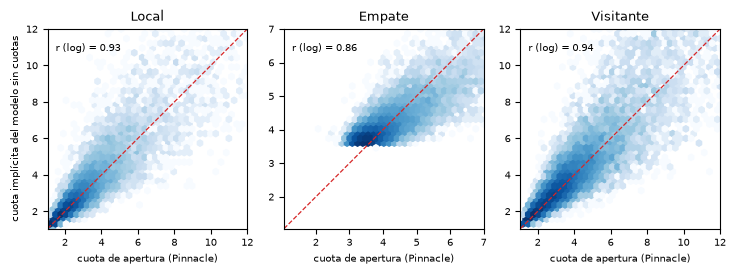

In [5]:
oof6 = pd.read_csv(DATA + 'predicciones_oof.csv'); assert (oof6.y.values == y[oof6.idx.values]).all()
P_NM = full(oof6[['P_NM_H', 'P_NM_D', 'P_NM_A']].to_numpy(float), oof6.idx.values); P_M6 = full(oof6[['P_M_H', 'P_M_D', 'P_M_A']].to_numpy(float), oof6.idx.values)
P_prior = P4['prior'] if 'prior' in P4 else full(oof4[['prior|H', 'prior|D', 'prior|A']].to_numpy(float), oof4.idx.values)
L_nm, L_m6, L_prior = loss_vec(P_NM), loss_vec(P_M6), loss_vec(P_prior)
filas = []
for k, P in (('prior', P_prior), ('mercado crudo (consenso)', Pmk_ev), ('Pinnacle cruda (con respaldo)', Ppin_ev), ('cuotas -> GD -> prob. (06)', P_M6), ('SIN CUOTAS -> GD -> prob. (06)', P_NM)):
    m = metricas(P); nd = EV & (y != 1); m['acierto_ganador'] = float((P[nd].argmax(1) == y[nd]).mean()); filas.append(dict(modelo=k, **m))
pc = pd.DataFrame(filas).set_index('modelo'); print(pc[['n', 'log_loss', 'RPS', 'AUC_macro', 'ECE_masa', 'acc', 'acierto_ganador']].round(4).to_string())
ll = pc.log_loss; gan_mk, gan_nm = ll['prior'] - ll['mercado crudo (consenso)'], ll['prior'] - ll['SIN CUOTAS -> GD -> prob. (06)']
print(f"\nganancia sobre el prior -> mercado: {gan_mk:.4f} | sin cuotas: {gan_nm:.4f} | fraccion reproducida: {gan_nm / gan_mk:.1%}")
print(f"acierto del ganador -> sin cuotas / mercado: {pc.acierto_ganador['SIN CUOTAS -> GD -> prob. (06)'] / pc.acierto_ganador['mercado crudo (consenso)']:.1%} | AUC: {pc.AUC_macro['SIN CUOTAS -> GD -> prob. (06)'] / pc.AUC_macro['mercado crudo (consenso)']:.1%}")
# --- parecido entre nuestro precio y el del mercado (validacion)
ok = EV & ~np.isnan(P_NM[:, 0]); lg_nm, lg_mk = np.log(P_NM[ok, 0] / P_NM[ok, 2]), np.log(Pmk[ok, 0] / Pmk[ok, 2])
r_logit, r_pD = np.corrcoef(lg_nm, lg_mk)[0, 1], np.corrcoef(P_NM[ok, 1], Pmk[ok, 1])[0, 1]
b1, b0 = np.polyfit(lg_mk, lg_nm, 1); r2 = 1 - np.sum((lg_nm - (b0 + b1 * lg_mk)) ** 2) / np.sum((lg_nm - lg_nm.mean()) ** 2)
fav = (P_NM[ok].argmax(1) == Pmk[ok].argmax(1)).mean(); mad = np.abs(P_NM[ok] - Pmk[ok]).mean(0)
print(f"\ncorrelacion logit(pH/pA) propio vs mercado: {r_logit:.3f} (R2 {r2:.3f}, pendiente {b1:.2f}) | correlacion P(empate): {r_pD:.3f}")
print(f"mismo favorito: {fav:.1%} | diferencia media absoluta de probabilidad H/D/A: {mad[0]:.3f} / {mad[1]:.3f} / {mad[2]:.3f}")
c_nm = comparar(L_nm, L_mk); print(f"sin cuotas - mercado (log loss): {c_nm['delta']:+.4f} [{c_nm['lo']:+.4f}, {c_nm['hi']:+.4f}], temporadas en que gana: {c_nm['folds']}")
por_temp = pd.DataFrame([dict(temporada=int(s), n=int((ok & (seas == s)).sum()), ll_sin_cuotas=float(np.nanmean(L_nm[seas == s])), ll_mercado=float(np.nanmean(L_mk[seas == s])), ll_prior=float(np.nanmean(L_prior[seas == s])),
                              **{k: v for k, v in comparar(L_nm, L_mk, mask=(seas == s)).items() if k in ('delta', 'lo', 'hi')}) for s in FOLDS])
por_temp['fraccion_reproducida'] = (por_temp.ll_prior - por_temp.ll_sin_cuotas) / (por_temp.ll_prior - por_temp.ll_mercado); print('\n' + por_temp.round(4).to_string(index=False))
res_pc = pc.copy(); res_pc.loc['SIN CUOTAS -> GD -> prob. (06)', ['corr_logit', 'corr_pD', 'mismo_favorito', 'fraccion_ganancia_prior']] = [r_logit, r_pD, fav, gan_nm / gan_mk]; res_pc.to_csv(DATA + 'predictor_cuotas.csv')

# --- figura: nuestra cuota implicita frente a la de Pinnacle (apertura; consenso donde Pinnacle no publica)
keycols = ['Season', 'Date', 'HomeTeam', 'AwayTeam']; ms = pd.read_csv(DATA + 'matches_clean.csv', usecols=keycols + ['PSH', 'PSD', 'PSA'])
PS = df[keycols].merge(ms, on=keycols, how='left', validate='one_to_one')[['PSH', 'PSD', 'PSA']].to_numpy(float)
cuota_mk = np.where(np.isnan(PS), 1 / Pmk, PS); cuota_nm = 1 / P_NM
fig, axs = plt.subplots(1, 3, figsize=(7.4, 2.75))
for j, (ax, lab) in enumerate(zip(axs, ('Local', 'Empate', 'Visitante'))):
    xm, ym = cuota_mk[ok, j], cuota_nm[ok, j]; lim = (1.05, 12 if j != 1 else 7)
    ax.hexbin(xm, ym, gridsize=38, bins='log', cmap='Blues', extent=(lim[0], lim[1], lim[0], lim[1]), mincnt=1); ax.plot(lim, lim, color='tab:red', lw=0.9, ls='--')
    r_ = np.corrcoef(np.log(xm), np.log(ym))[0, 1]; ax.text(0.04, 0.93, f'r (log) = {r_:.2f}', transform=ax.transAxes, fontsize=7, va='top')
    ax.set_xlim(lim); ax.set_ylim(lim); ax.set_title(lab, fontsize=9); ax.set_xlabel('cuota de apertura (Pinnacle)', fontsize=7); ax.tick_params(labelsize=7); ax.set_aspect('equal')
axs[0].set_ylabel('cuota implícita del modelo sin cuotas', fontsize=7)
plt.tight_layout(); plt.savefig(FIG + 'p_predictor_cuotas.png', dpi=200, bbox_inches='tight'); plt.show()

**Qué encontramos.** En validación (18,184 partidos) el modelo sin cuotas obtiene log loss **0.9821**, RPS 0.1998, AUC macro 0.665, ECE 0.0147 y acierto 52.7%, frente a 0.9664, 0.1953, 0.684, 0.0143 y 53.8% del mercado crudo (prior: 1.0720, AUC 0.50, acierto 43.8%). La diferencia de log loss es +0.0157 [+0.0135, +0.0178] y el mercado gana en las 6 temporadas, pero el modelo sin cuotas **reproduce el 85% de la ganancia del mercado sobre el prior** (0.0899 de 0.1055; entre 82% y 89% según la temporada), el 98% de su acierto del ganador (70.1% frente a 71.6%) y el 97% de su AUC. Nuestro precio y el de Pinnacle se parecen: correlación 0.942 entre los logits $\ln(p_H/p_A)$ (R² 0.887, pendiente 0.99, es decir, sin encogimiento sistemático), 0.848 entre las probabilidades de empate, el mismo favorito en el 89.8% de los partidos y una diferencia media absoluta de 4.9, 2.0 y 4.4 puntos porcentuales en H, D y A. La figura muestra que las cuotas implícitas se agrupan sobre la diagonal, con más dispersión en los favoritos grandes y en el empate (la cuota de empate del modelo varía poco: entre 3.3 y 5, mientras Pinnacle llega a 7).

**Qué significa para nuestro caso.** Con información pública (ratings de jugadores y resultados pasados) se genera un predictor de cuotas que explica casi el 90% de la variación del precio del mercado y recupera el 85% de su valor predictivo. El 15% restante (0.016 de log loss) es la medida de lo que el mercado sabe y nuestras variables no: alineaciones, lesiones, dinero informado y, en parte, mejores modelos. Esa brecha es también la razón de que el modelo sin cuotas no genere apuestas rentables (`06_mercado`, Paso 7): sus discrepancias con el precio están justo en ese 15%.

**Decisión.** Presentar este resultado como subsección propia en el informe ("el modelo sin cuotas como predictor de cuotas") con la Fig. `p_predictor_cuotas.png` y un cuadro con estas métricas; es el énfasis que sugiere el profesor cuando la mejora sobre las cuotas crudas es marginal.

## Paso 5 — Cuadro único de comparación directa (validación y test holdout)

**Qué vamos a hacer.** Reunir en un solo cuadro, con las mismas métricas, todo lo que compite con las cuotas usadas de forma directa: el *prior*, el mercado crudo (consenso), Pinnacle cruda, el *baseline*, el modelo final, el modelo sin cuotas, la mejor variante con pesos del Paso 1 y el mejor ensemble del Paso 3, en validación (6 temporadas) y, para las filas que `08_modelo_final` ya evaluó, en el test holdout (las predicciones del test se **leen** del archivo que generó el cuaderno 08 y las referencias se reproducen con el mismo código; nada nuevo se evalúa en el test). Cada fila se compara con el consenso crudo (Δ de log loss con intervalo por bloques).

**Por qué.** El profesor pide ver, de forma directa, si algún modelo mejora a las cuotas; un cuadro único evita que la respuesta quede repartida en varios cuadernos y deja explícito cuánto (poco) aporta cada enfoque sobre el precio.

In [6]:
fin_oof = pd.read_csv(DATA + 'modelo_final_oof.csv'); fin_test = pd.read_csv(DATA + 'modelo_final_test.csv')
P_fin = full(fin_oof[['P_H', 'P_D', 'P_A']].to_numpy(float), fin_oof.idx.to_numpy(int)); P_fin_t = full(fin_test[['P_H', 'P_D', 'P_A']].to_numpy(float), fin_test.idx.to_numpy(int))
assert (fin_oof.y.to_numpy(int) == y[fin_oof.idx.to_numpy(int)]).all() and (fin_test.y.to_numpy(int) == y[fin_test.idx.to_numpy(int)]).all()
assert np.isnan(P_fin[TEST_MASK]).all() and (~np.isnan(P_fin_t[TEST_MASK, 0])).all() and np.isnan(P_fin_t[TV, 0]).all()
# referencias en el test (misma construccion que 08, Paso 8): prior de train/val, consenso, Pinnacle, baseline entrenado solo con train/val
prior_tv = np.bincount(y[TV], minlength=3) / TV.sum(); PA_t = np.full((len(y), 3), np.nan); PA_t[TEST_MASK] = lr(HP['LR_clas']['C'])().fit(X_MKT[TV], y[TV]).predict_proba(X_MKT[TEST_MASK])
mejor_peso = pesos[(pesos.esquema != 'sin pesos')].sort_values('log_loss').iloc[0]; mejor_ens = ens[ens.modelo != 'LR (cuotas), baseline'].sort_values('log_loss').iloc[0]
print('mejor variante con pesos:', mejor_peso.modelo, '|', mejor_peso.esquema, '| mejor ensemble:', mejor_ens.modelo)
FILAS = [('Prior', P_prior, np.where(TEST_MASK[:, None], prior_tv, np.nan)), ('Mercado crudo (consenso de 4 casas)', Pmk_ev, np.where(TEST_MASK[:, None], Pmk, np.nan)),
         ('Pinnacle cruda (respaldo: consenso)', Ppin_ev, np.where(TEST_MASK[:, None], Ppin, np.nan)), ('Baseline: LR 3 var. sobre consenso', P4['LR (cuotas)'], PA_t),
         ('Modelo final: LR 2 var. sobre Pinnacle', P_fin, P_fin_t), ('Modelo sin cuotas (fundamentos)', P_NM, None),
         (f'Mejor con pesos: {mejor_peso.modelo}, {mejor_peso.esquema}', P_pesos[(mejor_peso.modelo, mejor_peso.esquema)], None), (f'Mejor ensemble: {mejor_ens.modelo}', ENS[mejor_ens.modelo], None)]
filas = []
for nombre, Pv, Pt in FILAS:
    mv = metricas(Pv, EV); cv_ = comparar(loss_vec(Pv), L_mk); fila = dict(modelo=nombre, val_log_loss=mv['log_loss'], val_delta_vs_consenso=cv_['delta'], val_IC=f"[{cv_['lo']:+.4f}, {cv_['hi']:+.4f}]", val_temporadas=cv_['folds'], val_AUC=mv['AUC_macro'], val_ECE_masa=mv['ECE_masa'])
    if Pt is not None:
        mt = metricas(Pt, TEST_MASK); ct = comparar(loss_vec(Pt), loss_vec(np.where(TEST_MASK[:, None], Pmk, np.nan)), mask=TEST_MASK)
        fila.update(test_log_loss=mt['log_loss'], test_delta_vs_consenso=ct['delta'], test_IC=f"[{ct['lo']:+.4f}, {ct['hi']:+.4f}]", test_temporadas=ct['folds'], test_AUC=mt['AUC_macro'], test_ECE_masa=mt['ECE_masa'])
    filas.append(fila)
cd = pd.DataFrame(filas); cd.to_csv(DATA + 'comparacion_directa.csv', index=False)
assert abs(cd.loc[4, 'test_log_loss'] - 0.9651) < 0.0002 and abs(cd.loc[1, 'test_log_loss'] - 0.9667) < 0.0002
print('\n=== Validacion (6 temporadas, 18,184 partidos) ==='); print(cd[['modelo', 'val_log_loss', 'val_delta_vs_consenso', 'val_IC', 'val_temporadas', 'val_AUC', 'val_ECE_masa']].round(4).to_string(index=False))
print('\n=== Test holdout (2024/25-2025/26, 5,999 partidos; solo filas ya evaluadas en 08) ==='); print(cd.dropna(subset=['test_log_loss'])[['modelo', 'test_log_loss', 'test_delta_vs_consenso', 'test_IC', 'test_temporadas', 'test_AUC', 'test_ECE_masa']].round(4).to_string(index=False))

mejor variante con pesos: LR (cuotas), baseline | 50/50 por peso | mejor ensemble: Promedio ponderado (pesos anidados)



=== Validacion (6 temporadas, 18,184 partidos) ===
                                                modelo  val_log_loss  val_delta_vs_consenso             val_IC val_temporadas  val_AUC  val_ECE_masa
                                                 Prior        1.0720                 0.1055 [+0.1005, +0.1110]            0/6   0.4963        0.0121
                   Mercado crudo (consenso de 4 casas)        0.9664                 0.0000 [+0.0000, +0.0000]            0/6   0.6840        0.0143
                   Pinnacle cruda (respaldo: consenso)        0.9657                -0.0007 [-0.0010, -0.0005]            6/6   0.6847        0.0138
                    Baseline: LR 3 var. sobre consenso        0.9657                -0.0007 [-0.0015, +0.0000]            5/6   0.6836        0.0087
                Modelo final: LR 2 var. sobre Pinnacle        0.9653                -0.0011 [-0.0018, -0.0005]            5/6   0.6844        0.0093
                       Modelo sin cuotas (fundamentos)

**Qué encontramos.** Validación (6 temporadas; Δ de log loss frente al consenso crudo, IC por bloques, temporadas en que gana al consenso):

| Modelo | Log loss | Δ vs consenso | IC 95% | Temp. | AUC | ECE (masa) |
|---|---|---|---|---|---|---|
| Prior | 1.0720 | +0.1055 | [+0.1005, +0.1110] | 0/6 | 0.496 | 0.0121 |
| Mercado crudo (consenso de 4 casas) | 0.9664 | 0 | — | — | 0.684 | 0.0143 |
| Pinnacle cruda (respaldo: consenso) | 0.9657 | −0.0007 | [−0.0010, −0.0005] | 6/6 | 0.685 | 0.0138 |
| *Baseline*: LR 3 var. sobre consenso | 0.9657 | −0.0007 | [−0.0015, +0.0000] | 5/6 | 0.684 | 0.0087 |
| **Modelo final: LR 2 var. sobre Pinnacle** | **0.9653** | **−0.0011** | [−0.0018, −0.0005] | 5/6 | 0.684 | 0.0093 |
| Modelo sin cuotas (fundamentos) | 0.9821 | +0.0157 | [+0.0135, +0.0178] | 0/6 | 0.665 | 0.0147 |
| Mejor con pesos (LR, 50/50 por peso) | 0.9676 | +0.0012 | [+0.0003, +0.0021] | 0/6 | 0.684 | 0.0201 |
| Mejor ensemble (promedio ponderado) | 0.9661 | −0.0004 | [−0.0011, +0.0004] | 4/6 | 0.683 | 0.0085 |

Test holdout (2024/25–2025/26, 5,999 partidos; solo las filas que `08` ya evaluó): prior 1.0750; consenso 0.9667; Pinnacle cruda 0.9660 (−0.0007 [−0.0010, −0.0003], 2/2); *baseline* 0.9652 (−0.0015 [−0.0026, −0.0004], 2/2); **modelo final 0.9651** (−0.0016 [−0.0026, −0.0005], 2/2; AUC 0.683, ECE 0.0168). Las cifras reproducen las de `08_modelo_final` (0.9651 y 0.9667, verificadas con `assert`).

**Qué significa para nuestro caso.** Leído de forma directa contra las cuotas: (1) Pinnacle cruda ya es mejor que el consenso (−0.0007, 6/6 y 2/2); (2) el modelo final gana al consenso en 0.0011 (validación) y 0.0016 (test), pero solo 0.0004 y 0.0009 a Pinnacle cruda, y nada al *baseline*; (3) nada de lo nuevo (pesos, remuestreo, ensembles) se acerca siquiera a la LR; (4) el modelo sin cuotas queda a 0.016 del mercado. Un modelo sobre las cuotas aporta, como mucho, una recalibración de una milésima de log loss; la información está en el precio.

**Decisión.** Este cuadro reemplaza en el informe a las cifras dispersas de la sección de test, con las columnas de validación y test lado a lado.

## Resumen — respuesta a cada punto del profesor

| Punto del profesor | Qué se hizo | Resultado |
|---|---|---|
| **¿Ensembles y PCA?** | PCA: `04_modelo`, Paso 9 (MI frente a PCA, con y sin cuotas). Ensembles: promedio de 5 (`04`), y aquí promedio sin SVM, promedio ponderado anidado, *stacking* y Random Forest (Paso 3). | Ningún ensemble supera a la LR (el mejor, promedio ponderado, +0.0003 [+0.0000, +0.0006]) y el propio ensemble asigna a la LR el 83–98% del peso. Con cuotas MI > PCA porque conserva la variable dominante; sin cuotas PCA ≥ MI; reducir variables no mejora a usar todas. |
| **Pesos por muestra / remuestreo 50/50** (*data-centric*) | 7 esquemas de peso y 2 de remuestreo × 4 modelos × 6 temporadas, con recalibración posterior (Pasos 1–2). | Todo empeora el log loss (+0.002 con el peso suave, +0.04 a +0.26 con w ≥ 2), 0/6 temporadas, *p* < 0.001. Sube el acierto en sorpresas y el *recall* del empate (0.1% → 44% con w = 2) porque el modelo predice más empates, no porque los identifique: es un cambio de *prior*, no información. La recalibración posterior devuelve el modelo remuestreado casi al punto de partida (+0.0010). |
| **Comparar directamente con las cuotas** | Cuadro único validación + test (Paso 5). | Pinnacle cruda ya gana al consenso (−0.0007). El modelo final gana 0.0011/0.0016 al consenso, 0.0004/0.0009 a Pinnacle cruda y nada al *baseline*: una LR sobre el precio solo lo recalibra. Cualquier otro modelo sobre las cuotas está de más. |
| **Énfasis en el experimento sin cuotas** | El modelo de fundamentos como predictor de cuotas (Paso 4). | Reproduce el 85% de la ganancia del mercado sobre el prior, el 98% de su acierto del ganador, correlación 0.94 con el logit de Pinnacle y el mismo favorito en el 90% de los partidos; queda a 0.016 de log loss (0/6 temporadas), que es la medida de lo que el mercado sabe y nuestras variables no. |

**Qué cambia en el informe.** Metodología: pesos/remuestreo, *stacking* y Random Forest. Resultados: subsección de pesos y ensembles (Fig. `p_pesos.png`, Fig. `p_ensembles.png`), subsección del predictor de cuotas (Fig. `p_predictor_cuotas.png`) y cuadro único de comparación directa. Discusión: por qué reponderar empeora una regla de puntuación propia. Conclusiones: respuesta a cada punto. El test holdout **no** se ha vuelto a usar para ninguna decisión.